# Data Understanding and Preparation

Industry Track · Resume–Job Matching System

This notebook loads, studies, cleans, and splits the resume–job dataset.

## Background

We reviewed five resume-job matching papers before selecting the dataset and reference methods. The review helped us weigh task fit, data access, evaluation measures, and computing cost. This notebook studies and prepares the chosen data so the modelling decisions rest on documented evidence. See the [related-work overview](../../m1/related-work.md).

## Objectives

1. Check dataset fields, labels, missing values, and document lengths.
2. Identify duplicate pairs, conflicting labels, and split overlap.
3. Clean text and replace direct contact details.
4. Create repeatable training, validation, and test data.
5. Report privacy and evaluation limits.

The resulting splits provide consistent inputs for model comparison.

## Run

Use a Google Colab CPU runtime and run cells in order. Install the versions in `m2/requirements.txt` for the recorded environment. The first cell installs the tested package versions. Dataset download requires internet access. Random seed: 42.

The notebook keeps prepared data in memory. Do not save or publish real resume records.


In [1]:
%pip install -q datasets==4.8.3 matplotlib==3.10.8 numpy==2.4.3 pandas==3.0.1 scikit-learn==1.8.0 seaborn==0.13.2

import sys
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import datasets

from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
NOTEBOOK_START_TIME = time.time()

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Setup complete")
print(f"Python: {sys.version.split()[0]}")
print(f"datasets: {datasets.__version__}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Random seed: {SEED}")

Setup complete
Python: 3.14.0
datasets: 4.8.3
pandas: 3.0.1
NumPy: 2.4.3
scikit-learn: 1.8.0
Matplotlib: 3.10.8
Seaborn: 0.13.2
Random seed: 42


In [2]:
DATASET_NAME = "cnamuangtoun/resume-job-description-fit"

dataset = load_dataset(DATASET_NAME)

print(f"Dataset: {DATASET_NAME}")
print(dataset)

for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data):,} rows")

Using the latest cached version of the dataset since cnamuangtoun/resume-job-description-fit couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /tmp/resume-matcher-m2-validation/huggingface/datasets/cnamuangtoun___resume-job-description-fit/default/0.0.0/08978e21714984bb417547d2c0f9b477f5298163 (last modified on Sun Nov 15 09:52:13 2026).


Dataset: cnamuangtoun/resume-job-description-fit
DatasetDict({
    train: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 6241
    })
    test: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 1759
    })
})
train: 6,241 rows
test: 1,759 rows


In [3]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nData types:")
print(train_df.dtypes)


Training shape: (6241, 3)
Test shape: (1759, 3)

Columns: ['resume_text', 'job_description_text', 'label']

Data types:
resume_text             str
job_description_text    str
label                   str
dtype: object


In [4]:
label_order = ["Good Fit", "Potential Fit", "No Fit"]

all_labels = sorted(
    set(train_df["label"].dropna()) | set(test_df["label"].dropna())
)

print("Labels found:", all_labels)

label_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(label_order).fillna(0).astype(int)

label_counts["Total"] = label_counts["Train"] + label_counts["Test"]
label_counts["Total (%)"] = (
    label_counts["Total"] / label_counts["Total"].sum() * 100
).round(2)

display(label_counts)

Labels found: ['Good Fit', 'No Fit', 'Potential Fit']


,Train,Test,Total,Total (%)
label,,,,
Good Fit,1542,458,2000,25.0
Potential Fit,1556,444,2000,25.0
No Fit,3143,857,4000,50.0


In [5]:
def missing_value_summary(dataframe):
    missing = dataframe.isna().sum()
    empty = dataframe.apply(
        lambda column: column.dropna().astype(str).str.strip().eq("").sum()
    )

    return pd.DataFrame({
        "Missing values": missing,
        "Empty values": empty,
        "Total affected": missing + empty
    })

missing_summary = pd.concat(
    {
        "Train": missing_value_summary(train_df),
        "Test": missing_value_summary(test_df)
    },
    names=["Split", "Column"]
)

display(missing_summary)

Missing values  Empty values  Total affected
Split Column                                                            
Train resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0
Test  resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0

In [6]:
PAIR_COLUMNS = ["resume_text", "job_description_text"]

def find_duplicate_pairs(dataframe):
    groups = (
        dataframe.groupby(PAIR_COLUMNS, dropna=False)
        .agg(
            row_count=("label", "size"),
            unique_labels=("label", "nunique"),
            labels=("label", lambda values: sorted(values.unique()))
        )
        .reset_index()
    )
    return groups[groups["row_count"] > 1].copy()

train_duplicate_groups = find_duplicate_pairs(train_df)
test_duplicate_groups = find_duplicate_pairs(test_df)

duplicate_summary = pd.DataFrame({
    "Train": [
        len(train_duplicate_groups),
        train_duplicate_groups["row_count"].sum(),
        (train_duplicate_groups["unique_labels"] > 1).sum(),
        (train_duplicate_groups["unique_labels"] == 1).sum()
    ],
    "Test": [
        len(test_duplicate_groups),
        test_duplicate_groups["row_count"].sum(),
        (test_duplicate_groups["unique_labels"] > 1).sum(),
        (test_duplicate_groups["unique_labels"] == 1).sum()
    ]
}, index=[
    "Duplicate groups",
    "Rows in duplicate groups",
    "Conflicting-label groups",
    "Same-label groups"
])

display(duplicate_summary)

print("\nTraining duplicate-group details:")
display(
    train_duplicate_groups[
        ["row_count", "unique_labels", "labels"]
    ].reset_index(drop=True)
)

,Train,Test
Duplicate groups,7,0
Rows in duplicate groups,14,0
Conflicting-label groups,6,0
Same-label groups,1,0



Training duplicate-group details:


,row_count,unique_labels,labels
0,2,2,"[No Fit, Potential Fit]"
1,2,2,"[Good Fit, No Fit]"
2,2,2,"[Good Fit, No Fit]"
3,2,2,"[Good Fit, No Fit]"
4,2,2,"[No Fit, Potential Fit]"
5,2,1,[No Fit]
6,2,2,"[Good Fit, No Fit]"


In [7]:
def calculate_overlap(train_values, test_values):
    train_values = list(train_values)
    test_values = list(test_values)

    train_set = set(train_values)
    test_set = set(test_values)
    shared_values = train_set & test_set
    test_overlap_count = sum(value in train_set for value in test_values)

    return {
        "Train unique": len(train_set),
        "Test unique": len(test_set),
        "Shared unique": len(shared_values),
        "Test rows with overlap": test_overlap_count,
        "Test overlap (%)": round(test_overlap_count / len(test_values) * 100, 2)
    }

train_pairs = list(zip(train_df["resume_text"], train_df["job_description_text"]))
test_pairs = list(zip(test_df["resume_text"], test_df["job_description_text"]))

overlap_summary = pd.DataFrame({
    "Resume text": calculate_overlap(
        train_df["resume_text"], test_df["resume_text"]
    ),
    "Job description": calculate_overlap(
        train_df["job_description_text"], test_df["job_description_text"]
    ),
    "Resume-job pair": calculate_overlap(train_pairs, test_pairs)
}).T

display(overlap_summary)

,Train unique,Test unique,Shared unique,Test rows with overlap,Test overlap (%)
Resume text,642.0,477.0,476.0,1758.0,99.94
Job description,280.0,71.0,0.0,0.0,0.00
Resume-job pair,6234.0,1759.0,0.0,0.0,0.00


In [8]:
analysis_df = pd.concat(
    [
        train_df.assign(split="Train"),
        test_df.assign(split="Test")
    ],
    ignore_index=True
)

analysis_df["resume_words"] = (
    analysis_df["resume_text"].astype(str).str.split().str.len()
)
analysis_df["job_words"] = (
    analysis_df["job_description_text"].astype(str).str.split().str.len()
)
analysis_df["resume_characters"] = (
    analysis_df["resume_text"].astype(str).str.len()
)
analysis_df["job_characters"] = (
    analysis_df["job_description_text"].astype(str).str.len()
)

length_summary = analysis_df.groupby("split").agg(
    resume_words_mean=("resume_words", "mean"),
    resume_words_median=("resume_words", "median"),
    resume_words_max=("resume_words", "max"),
    job_words_mean=("job_words", "mean"),
    job_words_median=("job_words", "median"),
    job_words_max=("job_words", "max"),
    resume_characters_mean=("resume_characters", "mean"),
    job_characters_mean=("job_characters", "mean")
).round(1)

display(length_summary)

,resume_words_mean,resume_words_median,resume_words_max,job_words_mean,job_words_median,job_words_max,resume_characters_mean,job_characters_mean
split,,,,,,,,
Test,691.4,618.0,2738,402.9,308.0,1254,5663.3,2939.2
Train,708.1,618.0,3134,371.5,328.0,1079,5804.4,2731.3


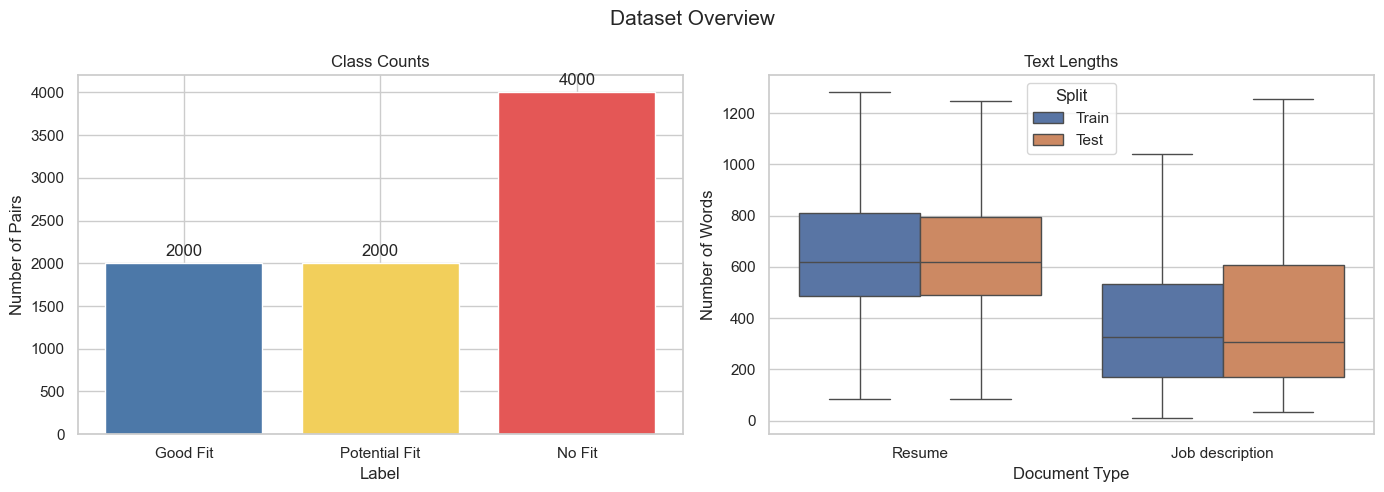

Figure saved to: m2/figures/dataset-overview.png


In [9]:
from pathlib import Path

FIGURE_DIR = Path("m2/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

total_label_counts = (
    analysis_df["label"]
    .value_counts()
    .reindex(label_order)
)

length_plot_df = analysis_df[
    ["split", "resume_words", "job_words"]
].melt(
    id_vars="split",
    var_name="document_type",
    value_name="word_count"
)

length_plot_df["document_type"] = length_plot_df["document_type"].replace({
    "resume_words": "Resume",
    "job_words": "Job description"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(
    total_label_counts.index,
    total_label_counts.values,
    color=["#4C78A8", "#F2CF5B", "#E45756"]
)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Class Counts")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Number of Pairs")

sns.boxplot(
    data=length_plot_df,
    x="document_type",
    y="word_count",
    hue="split",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Text Lengths")
axes[1].set_xlabel("Document Type")
axes[1].set_ylabel("Number of Words")
axes[1].legend(title="Split")

fig.suptitle("Dataset Overview", fontsize=15)
plt.tight_layout()

figure_path = FIGURE_DIR / "dataset-overview.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")

In [10]:
dataset_info = dataset["train"].info
DATASET_URL = f"https://huggingface.co/datasets/{DATASET_NAME}"

def show_metadata(value):
    if value is None or str(value).strip() == "":
        return "Not provided"
    return str(value).strip()

dataset_metadata = pd.DataFrame({
    "Value": [
        DATASET_NAME,
        DATASET_URL,
        show_metadata(dataset_info.description),
        show_metadata(dataset_info.license),
        show_metadata(dataset_info.homepage),
        show_metadata(dataset_info.citation)
    ]
}, index=[
    "Dataset name",
    "Dataset page",
    "Description",
    "Licence",
    "Homepage",
    "Citation"
])

display(dataset_metadata)

,Value
Dataset name,cnamuangtoun/resume-job-description-fit
Dataset page,https://huggingface.co/datasets/cnamuangtoun/resume-job-description-fit
Description,Not provided
Licence,Not provided
Homepage,Not provided
Citation,Not provided


## Dataset Audit Findings

The `resume-job-description-fit` dataset is publicly available on Hugging Face. It contains resume-job pairs labelled as Good Fit, Potential Fit, or No Fit.

### Dataset Structure

| Split | Rows |
|---|---:|
| Training | 6,241 |
| Test | 1,759 |
| Total | 8,000 |

The dataset contains three columns:

- `resume_text`
- `job_description_text`
- `label`

### Label Distribution

| Label | Total rows | Percentage |
|---|---:|---:|
| Good Fit | 2,000 | 25% |
| Potential Fit | 2,000 | 25% |
| No Fit | 4,000 | 50% |

The No Fit class contains half of the dataset. Macro-F1 is therefore used as the main metric so that every class receives equal importance.

### Data Quality

- No missing values were found.
- No empty text or label values were found.
- The training split contains seven duplicate resume-job groups.
- Six duplicate groups contain conflicting labels.
- One duplicate group contains the same label.
- The test split contains no duplicate resume-job pairs.

Conflicting pairs are removed before splitting.

### Split Overlap

- 476 unique resumes appear in both training and test data.
- 1,758 of the 1,759 test rows use a resume that also appears in training.
- No job descriptions are shared between training and test.
- No complete resume-job pairs are shared between training and test.

There is no exact pair overlap. However, the high resume overlap means that the test split mainly checks known resumes against new job descriptions.

### Dataset Information Limitations

The Hugging Face dataset page does not provide:

- A detailed dataset description
- Licence information
- An official homepage
- A recommended citation
- Clear information about how the data was collected

Public access does not establish permission to reuse the data. The licence and source must be confirmed before broader use. Do not use this prototype for real hiring decisions.

In [11]:
audit_checks = {
    "Training rows equal 6,241": len(train_df) == 6241,
    "Test rows equal 1,759": len(test_df) == 1759,
    "Expected columns are present": train_df.columns.tolist() == [
        "resume_text", "job_description_text", "label"
    ],
    "Expected labels are present": set(all_labels) == {
        "Good Fit", "Potential Fit", "No Fit"
    },
    "No missing or empty values": (
        missing_summary["Total affected"].sum() == 0
    ),
    "Seven training duplicate groups": len(train_duplicate_groups) == 7,
    "Six conflicting duplicate groups": (
        train_duplicate_groups["unique_labels"].gt(1).sum() == 6
    ),
    "One same-label duplicate group": (
        train_duplicate_groups["unique_labels"].eq(1).sum() == 1
    ),
    "No test duplicate groups": len(test_duplicate_groups) == 0
}

audit_results = pd.DataFrame({
    "Check": audit_checks.keys(),
    "Passed": audit_checks.values()
})

display(audit_results)

if audit_results["Passed"].all():
    print("All dataset audit checks passed.")
else:
    print("Some dataset audit checks failed. Review the results above.")
assert audit_results["Passed"].all(), "Review the failed checks before continuing."


,Check,Passed
0,"Training rows equal 6,241",True
1,"Test rows equal 1,759",True
2,Expected columns are present,True
3,Expected labels are present,True
4,No missing or empty values,True
5,Seven training duplicate groups,True
6,Six conflicting duplicate groups,True
7,One same-label duplicate group,True
8,No test duplicate groups,True


All dataset audit checks passed.


---

## Preprocessing and Data Splits

This section prepares the dataset for baseline training.

The preprocessing steps are:

1. Remove conflicting duplicate pairs.
2. Keep one row from same-label duplicate pairs.
3. Convert text to lowercase.
4. Replace Markdown links with their visible text.
5. Replace emails, URLs, and phone numbers with placeholder words.
6. Remove unwanted characters.
7. Remove repeated spaces.
8. Create stratified training and validation splits using random seed 42.
9. Keep the official test split unchanged.

The expected final split sizes are:

| Split | Rows |
|---|---:|
| Training | 4,982 |
| Validation | 1,246 |
| Test | 1,759 |

In [12]:
import re

MARKDOWN_LINK_PATTERN = re.compile(r"\[([^\]]+)\]\([^)]+\)")
EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+")
PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)"
)
UNWANTED_CHARACTER_PATTERN = re.compile(r"[^a-z0-9+#.\s]")
WHITESPACE_PATTERN = re.compile(r"\s+")

def replace_phone_number(match):
    value = match.group()
    digit_count = len(re.sub(r"\D", "", value))
    return " phone " if digit_count >= 10 else value

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = MARKDOWN_LINK_PATTERN.sub(r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(replace_phone_number, text)
    text = UNWANTED_CHARACTER_PATTERN.sub(" ", text)
    text = WHITESPACE_PATTERN.sub(" ", text)

    return text.strip()

print("Text-cleaning function created.")

Text-cleaning function created.


In [13]:
example_text = """
Contact [Jane Doe](https://example.com/profile) at Jane.Doe@example.com.
Visit www.example.com or call +1 (555) 123-4567.
Skills: C++, C#, and machine-learning.
"""

cleaned_example = clean_text(example_text)

cleaning_checks = {
    "Visible link text kept": "jane doe" in cleaned_example,
    "Email replaced": " email " in f" {cleaned_example} ",
    "URL replaced": " url " in f" {cleaned_example} ",
    "Phone replaced": " phone " in f" {cleaned_example} ",
    "C++ kept": "c++" in cleaned_example,
    "C# kept": "c#" in cleaned_example,
    "Hyphen removed": "machine-learning" not in cleaned_example
}

print("Original text:")
print(example_text.strip())

print("\nCleaned text:")
print(cleaned_example)

display(pd.DataFrame({
    "Check": cleaning_checks.keys(),
    "Passed": cleaning_checks.values()
}))

assert all(cleaning_checks.values())

Original text:
Contact [Jane Doe](https://example.com/profile) at Jane.Doe@example.com.
Visit www.example.com or call +1 (555) 123-4567.
Skills: C++, C#, and machine-learning.

Cleaned text:
contact jane doe at email . visit url or call phone . skills c++ c# and machine learning.


,Check,Passed
0,Visible link text kept,True
1,Email replaced,True
2,URL replaced,True
3,Phone replaced,True
4,C++ kept,True
5,C# kept,True
6,Hyphen removed,True


In [14]:
pair_label_counts = (
    train_df.groupby(PAIR_COLUMNS, dropna=False)["label"]
    .transform("nunique")
)

conflicting_pair_mask = pair_label_counts > 1
rows_after_conflict_removal = train_df.loc[~conflicting_pair_mask].copy()

deduplicated_train_df = (
    rows_after_conflict_removal
    .drop_duplicates(subset=PAIR_COLUMNS, keep="first")
    .reset_index(drop=True)
)

conflicting_rows_removed = int(conflicting_pair_mask.sum())
same_label_rows_removed = (
    len(rows_after_conflict_removal) - len(deduplicated_train_df)
)

duplicate_removal_summary = pd.DataFrame({
    "Item": [
        "Original training rows",
        "Conflicting rows removed",
        "Same-label duplicate rows removed",
        "Clean training rows",
        "Official test rows"
    ],
    "Count": [
        len(train_df),
        conflicting_rows_removed,
        same_label_rows_removed,
        len(deduplicated_train_df),
        len(test_df)
    ]
})

display(duplicate_removal_summary)

remaining_duplicate_groups = find_duplicate_pairs(deduplicated_train_df)
print(f"Remaining duplicate groups: {len(remaining_duplicate_groups)}")

,Item,Count
0,Original training rows,6241
1,Conflicting rows removed,12
2,Same-label duplicate rows removed,1
3,Clean training rows,6228
4,Official test rows,1759


Remaining duplicate groups: 0


In [15]:
def add_cleaned_text_columns(dataframe):
    result = dataframe.copy()

    result["resume_text_clean"] = (
        result["resume_text"].map(clean_text)
    )
    result["job_description_text_clean"] = (
        result["job_description_text"].map(clean_text)
    )

    return result

processed_train_df = add_cleaned_text_columns(deduplicated_train_df)
processed_test_df = add_cleaned_text_columns(test_df.reset_index(drop=True))

cleaning_summary = pd.DataFrame([
    {
        "Split": split_name,
        "Document": document_name,
        "Rows": len(dataframe),
        "Changed rows": (
            dataframe[original_column] != dataframe[clean_column]
        ).sum(),
        "Empty after cleaning": dataframe[clean_column].eq("").sum(),
        "Mean characters before": dataframe[original_column].str.len().mean(),
        "Mean characters after": dataframe[clean_column].str.len().mean()
    }
    for split_name, dataframe in [
        ("Train", processed_train_df),
        ("Test", processed_test_df)
    ]
    for document_name, original_column, clean_column in [
        ("Resume", "resume_text", "resume_text_clean"),
        (
            "Job description",
            "job_description_text",
            "job_description_text_clean"
        )
    ]
])

cleaning_summary[
    ["Mean characters before", "Mean characters after"]
] = cleaning_summary[
    ["Mean characters before", "Mean characters after"]
].round(1)

display(cleaning_summary)

,Split,Document,Rows,Changed rows,Empty after cleaning,Mean characters before,Mean characters after
0,Train,Resume,6228,6228,0,5798.1,5672.6
1,Train,Job description,6228,6228,0,2731.3,2679.2
2,Test,Resume,1759,1759,0,5663.3,5538.6
3,Test,Job description,1759,1759,0,2939.2,2884.4


In [16]:
text_quality_rows = []

for split_name, dataframe in [
    ("Train", processed_train_df),
    ("Test", processed_test_df)
]:
    for document_name, column in [
        ("Resume", "resume_text_clean"),
        ("Job description", "job_description_text_clean")
    ]:
        values = dataframe[column]

        text_quality_rows.append({
            "Split": split_name,
            "Document": document_name,
            "No empty text": values.ne("").all(),
            "Lowercase": values.eq(values.str.lower()).all(),
            "Allowed characters only": (
                ~values.str.contains(
                    UNWANTED_CHARACTER_PATTERN,
                    regex=True
                ).any()
            ),
            "No repeated spaces": (
                ~values.str.contains(r"\s{2,}", regex=True).any()
            ),
            "No outer spaces": values.eq(values.str.strip()).all()
        })

text_quality_checks = pd.DataFrame(text_quality_rows)
display(text_quality_checks)

assert text_quality_checks.iloc[:, 2:].all().all()
print("All cleaned-text checks passed.")

,Split,Document,No empty text,Lowercase,Allowed characters only,No repeated spaces,No outer spaces
0,Train,Resume,True,True,True,True,True
1,Train,Job description,True,True,True,True,True
2,Test,Resume,True,True,True,True,True
3,Test,Job description,True,True,True,True,True


All cleaned-text checks passed.


In [17]:
from sklearn.model_selection import train_test_split

train_core_df, validation_df = train_test_split(
    processed_train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=processed_train_df["label"]
)

train_core_df = train_core_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_final_df = processed_test_df.reset_index(drop=True)

split_sizes = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Rows": [
        len(train_core_df),
        len(validation_df),
        len(test_final_df)
    ],
    "Expected rows": [4982, 1246, 1759]
})

split_sizes["Matches expected"] = (
    split_sizes["Rows"] == split_sizes["Expected rows"]
)

display(split_sizes)
print(f"Total cleaned rows: {split_sizes['Rows'].sum():,}")

,Split,Rows,Expected rows,Matches expected
0,Training,4982,4982,True
1,Validation,1246,1246,True
2,Test,1759,1759,True


Total cleaned rows: 7,987


In [18]:
split_dataframes = {
    "Training": train_core_df,
    "Validation": validation_df,
    "Test": test_final_df
}

split_label_counts = pd.DataFrame({
    split_name: dataframe["label"].value_counts()
    for split_name, dataframe in split_dataframes.items()
}).T.reindex(columns=label_order).fillna(0).astype(int)

split_label_counts["Total"] = split_label_counts.sum(axis=1)

expected_label_counts = pd.DataFrame(
    {
        "Good Fit": [1230, 308, 458],
        "Potential Fit": [1243, 311, 444],
        "No Fit": [2509, 627, 857],
        "Total": [4982, 1246, 1759]
    },
    index=["Training", "Validation", "Test"]
)

display(split_label_counts)

print(
    "Label counts match expected counts:",
    split_label_counts.equals(expected_label_counts)
)

label,Good Fit,Potential Fit,No Fit,Total
Training,1230,1243,2509,4982
Validation,308,311,627,1246
Test,458,444,857,1759


Label counts match expected counts: True


In [19]:
def get_pair_set(dataframe):
    return set(zip(
        dataframe["resume_text"],
        dataframe["job_description_text"]
    ))

def count_shared_values(first_df, second_df, column):
    return len(
        set(first_df[column]) & set(second_df[column])
    )

split_comparisons = [
    ("Training and validation", train_core_df, validation_df),
    ("Training and test", train_core_df, test_final_df),
    ("Validation and test", validation_df, test_final_df)
]

split_overlap_rows = []

for comparison, first_df, second_df in split_comparisons:
    split_overlap_rows.append({
        "Comparison": comparison,
        "Shared pairs": len(
            get_pair_set(first_df) & get_pair_set(second_df)
        ),
        "Shared resumes": count_shared_values(
            first_df, second_df, "resume_text"
        ),
        "Shared job descriptions": count_shared_values(
            first_df, second_df, "job_description_text"
        )
    })

split_overlap_summary = pd.DataFrame(split_overlap_rows)
display(split_overlap_summary)

test_columns = ["resume_text", "job_description_text", "label"]
test_is_unchanged = test_final_df[test_columns].equals(
    test_df.reset_index(drop=True)[test_columns]
)

print("Official test rows and labels unchanged:", test_is_unchanged)

,Comparison,Shared pairs,Shared resumes,Shared job descriptions
0,Training and validation,0,441,246
1,Training and test,0,473,0
2,Validation and test,0,368,0


Official test rows and labels unchanged: True


In [20]:
repeat_train_df, repeat_validation_df = train_test_split(
    processed_train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=processed_train_df["label"]
)

repeat_train_df = repeat_train_df.reset_index(drop=True)
repeat_validation_df = repeat_validation_df.reset_index(drop=True)

preprocessing_checks = {
    "Clean training data has 6,228 rows": (
        len(processed_train_df) == 6228
    ),
    "Training split has 4,982 rows": (
        len(train_core_df) == 4982
    ),
    "Validation split has 1,246 rows": (
        len(validation_df) == 1246
    ),
    "Test split has 1,759 rows": (
        len(test_final_df) == 1759
    ),
    "Label counts match expected counts": (
        split_label_counts.equals(expected_label_counts)
    ),
    "No training duplicate pairs": (
        len(find_duplicate_pairs(train_core_df)) == 0
    ),
    "No validation duplicate pairs": (
        len(find_duplicate_pairs(validation_df)) == 0
    ),
    "No test duplicate pairs": (
        len(find_duplicate_pairs(test_final_df)) == 0
    ),
    "No complete pair overlap": (
        split_overlap_summary["Shared pairs"].eq(0).all()
    ),
    "Official test data is unchanged": test_is_unchanged,
    "Split is repeatable with seed 42": (
        repeat_train_df.equals(train_core_df)
        and repeat_validation_df.equals(validation_df)
    )
}

preprocessing_results = pd.DataFrame({
    "Check": preprocessing_checks.keys(),
    "Passed": preprocessing_checks.values()
})

display(preprocessing_results)

if preprocessing_results["Passed"].all():
    print("All preprocessing and split checks passed.")
else:
    print("Some checks failed. Review the results above.")
assert preprocessing_results["Passed"].all(), "Review the failed checks before continuing."


,Check,Passed
0,"Clean training data has 6,228 rows",True
1,"Training split has 4,982 rows",True
2,"Validation split has 1,246 rows",True
3,"Test split has 1,759 rows",True
4,Label counts match expected counts,True
5,No training duplicate pairs,True
6,No validation duplicate pairs,True
7,No test duplicate pairs,True
8,No complete pair overlap,True
9,Official test data is unchanged,True


All preprocessing and split checks passed.


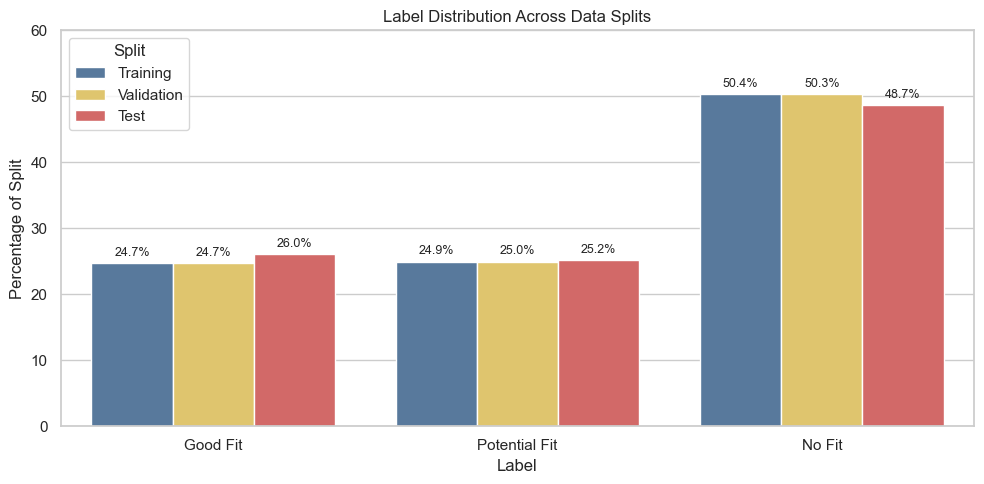

Figure saved to: m2/figures/split-label-distribution.png


In [21]:
split_label_percentages = (
    split_label_counts[label_order]
    .div(split_label_counts["Total"], axis=0)
    .mul(100)
    .round(2)
)

split_plot_df = (
    split_label_percentages
    .reset_index(names="Split")
    .melt(
        id_vars="Split",
        var_name="Label",
        value_name="Percentage"
    )
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=split_plot_df,
    x="Label",
    y="Percentage",
    hue="Split",
    palette=["#4C78A8", "#F2CF5B", "#E45756"],
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title("Label Distribution Across Data Splits")
ax.set_xlabel("Label")
ax.set_ylabel("Percentage of Split")
ax.set_ylim(0, 60)
ax.legend(title="Split")

plt.tight_layout()

split_figure_path = FIGURE_DIR / "split-label-distribution.png"
fig.savefig(split_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {split_figure_path}")

In [22]:
# Verify that cleaning did not create duplicate pairs or cross-split overlap.
clean_pair_columns = ["resume_text_clean", "job_description_text_clean"]
prepared_splits = {
    "Training": train_core_df,
    "Validation": validation_df,
    "Test": test_final_df,
}
clean_pair_sets = {
    name: set(dataframe[clean_pair_columns].itertuples(index=False, name=None))
    for name, dataframe in prepared_splits.items()
}
clean_pair_checks = {
    f"{name}: no duplicate cleaned pairs": not dataframe.duplicated(clean_pair_columns).any()
    for name, dataframe in prepared_splits.items()
}
for first, second in [("Training", "Validation"), ("Training", "Test"), ("Validation", "Test")]:
    clean_pair_checks[f"{first} / {second}: no shared cleaned pairs"] = not (
        clean_pair_sets[first] & clean_pair_sets[second]
    )
display(pd.DataFrame({"Check": clean_pair_checks.keys(), "Passed": clean_pair_checks.values()}))
assert all(clean_pair_checks.values()), "Cleaning created duplicate or shared pairs; review the splits."
print("All cleaned-pair checks passed.")


,Check,Passed
0,Training: no duplicate cleaned pairs,True
1,Validation: no duplicate cleaned pairs,True
2,Test: no duplicate cleaned pairs,True
3,Training / Validation: no shared cleaned pairs,True
4,Training / Test: no shared cleaned pairs,True
5,Validation / Test: no shared cleaned pairs,True


All cleaned-pair checks passed.


## Preprocessing Results

### Duplicate Handling

The original training split contained 6,241 rows.

- Six conflicting duplicate groups were removed completely.
- This removed 12 rows.
- One same-label duplicate group was reduced to one row.
- This removed one additional row.
- The final cleaned training data contains 6,228 rows.

No duplicate resume-job pairs remain after this step.

### Text Cleaning

The following steps were applied:

1. Convert text to lowercase.
2. Replace Markdown links with visible text.
3. Replace emails with `email`.
4. Replace URLs with `url`.
5. Replace phone numbers with `phone`.
6. Remove unwanted characters.
7. Keep letters, numbers, spaces, periods, plus signs, and number signs.
8. Replace repeated spaces with one space.
9. Remove spaces from the beginning and end.

No resume or job description became empty after cleaning.

Cleaning preserves C++ and C#. Model tokenization needs a separate check.

### Final Data Splits

The cleaned training data was divided using stratified sampling and random seed 42.

| Split | Good Fit | Potential Fit | No Fit | Total |
|---|---:|---:|---:|---:|
| Training | 1,230 | 1,243 | 2,509 | 4,982 |
| Validation | 308 | 311 | 627 | 1,246 |
| Test | 458 | 444 | 857 | 1,759 |

The split-distribution graph shows similar class percentages across the three splits.

The original test rows and labels were kept unchanged. Cleaning was applied only to create the text used by the models.

### Split Limitation

No complete resume-job pair appears in more than one split.

However, training and validation share 441 resumes and 246 job descriptions. The test split also shares many resumes with training and validation. This happens because the paper uses a pair-level split.

The official test split measures new jobs against largely known resumes. Validation shares jobs with training; Job-grouped validation would better represent unseen jobs during model selection. Both original-text and cleaned-text checks find no duplicate pairs within splits or shared pairs across splits.